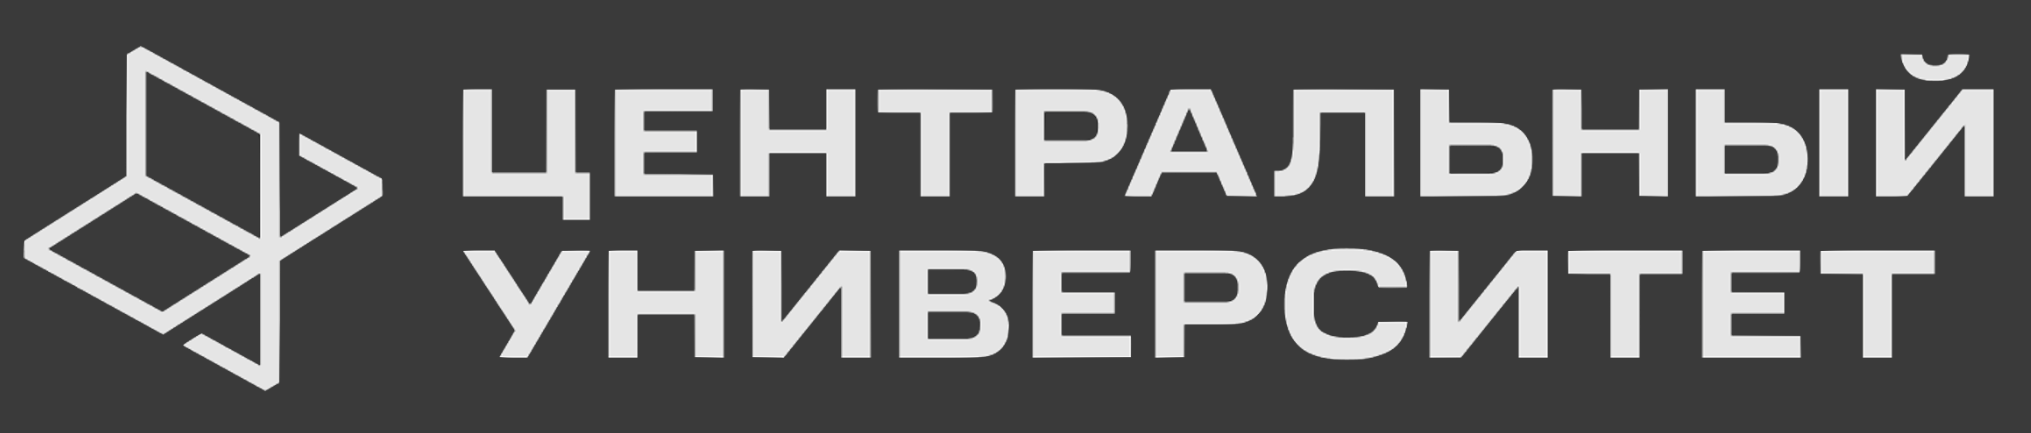

# Курс по прогнозированию временных рядов

# Неделя 11

## 11.3. Вероятностные прогнозы временных рядов с использованием TFT 

Мы будем использовать библиотеку Darts и сравним TFT с двумя базовыми методами прогнозирования.

Вероятностные прогнозы - это тип вывода, для которого хорошо подходят TFT и другие нейронные сети, после нескольких доработок их функций потерь.

Что такое Temporal Fusion Transformer?

TFT предлагает архитектуру нейронной сети, которая объединяет механизмы нескольких других нейронных архитектур, например, слои LSTM и головки внимания, используемые в трансформерах.

В недавней статье Google AI Blog - "Interpretable Deep Learning for Time Series Forecasting" (декабрь 2021 года) - представлен обзор Temporal Fusion Transformer. https://ai.googleblog.com/2021/12/interpretable-deep-learning-for-time.html 
Авторы протестировали TFT против альтернативных методов, таких как DeepAR, ARIMA и LSTM Seq2Sep. Они проверили их на четырех наборах данных и составили таблицу их производительности. TFT превзошла другие модели - как классические методы, так и нейронные сети различных типов. Его потери в 50% и 90% квантилях были ниже, по крайней мере, на 7%, чем у следующей лучшей модели - сети LSTM Seq2Seq.

Ранее, в конце 2020 года, в статье arxiv "Temporal Fusion Transformers for Interpretable Multi-horizon Time Series Forecasting" (arxiv.org) была представлена концепция TFT. https://arxiv.org/pdf/1912.09363.pdf

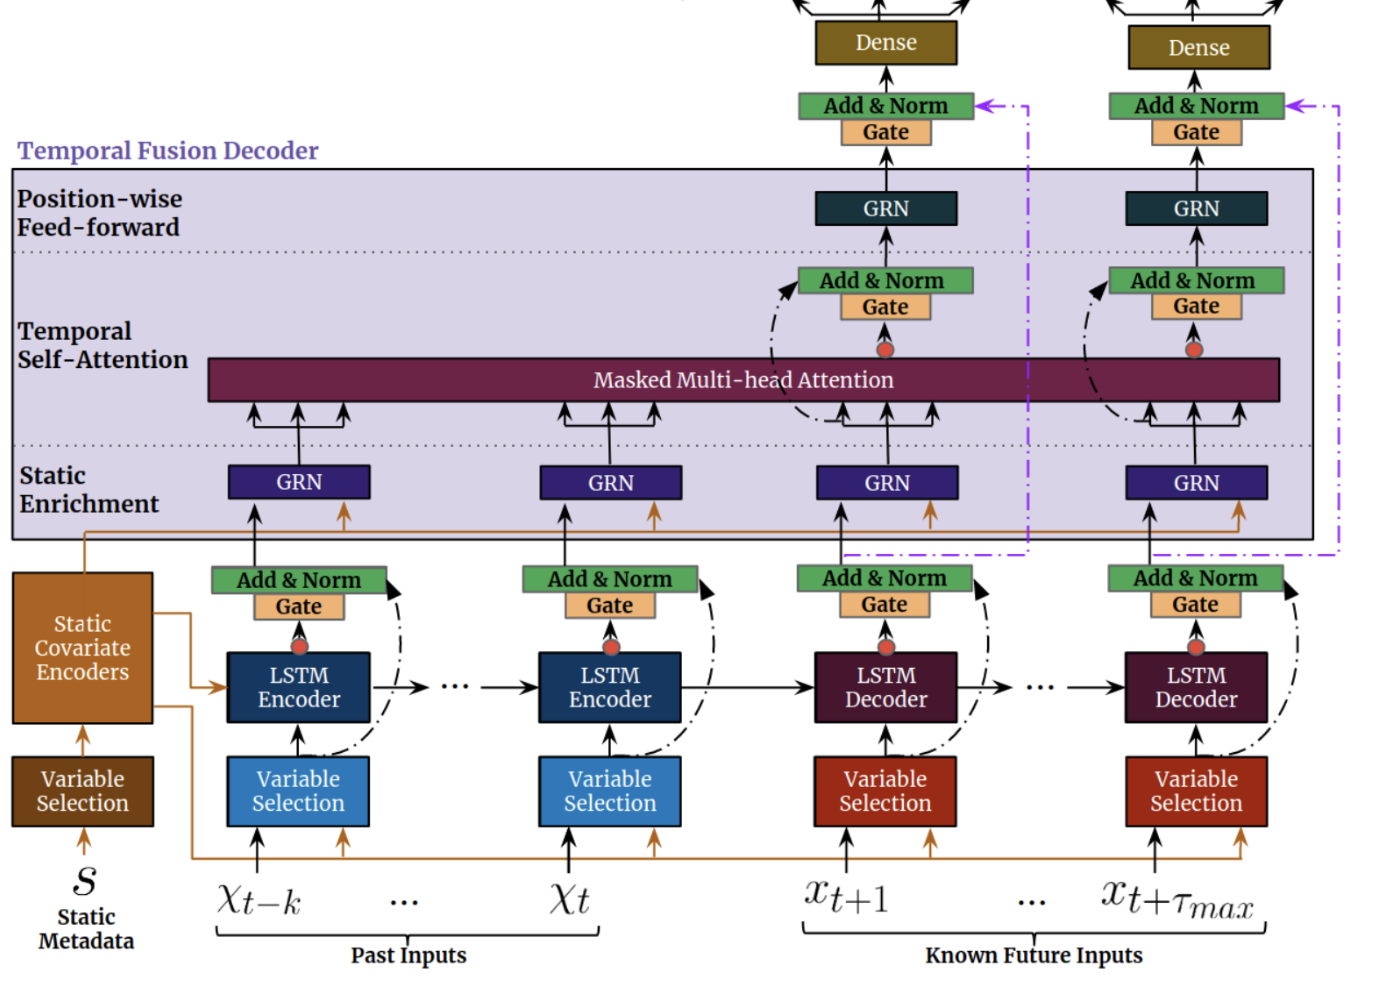

Основные строительные блоки специализируются на поиске различных аспектов или закономерностей во временном ряде, среди них:
- временной блок внимания с несколькими головками, который идентифицирует дальние паттерны временного ряда и определяет приоритетность наиболее значимых паттернов; каждая головка внимания может фокусироваться на отдельном временном паттерне;
- LSTM кодеры/декодеры последовательности для обобщения более коротких паттернов; блоки LSTM определяют связи временных шагов с их окружающими значениями (в то время как дальние связи остаются за головками внимания);
- блоки управляемой остаточной сети, GRN, которые должны отсеивать неважные, неиспользуемые входы. Они также могут случайным образом отбрасывать узлы для предотвращения переподгонки.

Декодер temporal fusion decoder получил свое название потому, что он объединяет эти специализированные слои для изучения взаимосвязей вдоль оси времени.

TFT минимизирует квантильную функцию потерь, что позволяет ему генерировать вероятностный прогноз.

TFT строит доверительные интервалы.


Пакет Darts служит оберткой для пакета PyTorch-forecasting. PyTorch реализует функцию квантильных потерь, которую Вен и др. описали в своей работе 2017 года (https://arxiv.org/pdf/1711.11053.pdf).

Квантильная функция потерь в PyTorch https://pytorch-forecasting.readthedocs.io/en/latest/api/pytorch_forecasting.metrics.QuantileLoss.html

In [ ]:
EPOCHS = 500
INLEN = 32          # длинна входного блока (input_chunk_length) или размер (количество узлов) входного слоя
HIDDEN = 64         # размер скрытого слоя (по эмпирическому правилу INLEN*2)
LSTMLAYERS = 1      # количество слоев для LSTM (в документации Darts по умолчанию 1)
ATTHEADS = 1        # для больших моделей, в которых можно ожидать проявления долгосрочных закономерностей, 
                    # можно выбрать до четырех головок. Для небольших и относительно простых наборов данных, 
                    # как в нашем примере, необходимо не более двух головок внимания
DROPOUT = 0.1    
BATCH = 32          # количество обучающих наблюдений, которые модель обрабатывает перед обновлением своих весов
                    # верхний предел определяется доступной памятью и количеством наблюдений
                    # маленькие партии подвержены большему шуму, градиентный спуск будет чаще менять свое направление

N_FC = 36           # горизонт прогнозирования
RAND = 42           # random state
N_SAMPLES = 100     # количество раз, когда предсказание выбирается из вероятностной модели
N_JOBS = 3          # parallel processors to use;  -1 = all processors

# default quantiles for Quantile Regression
QUANTILES = [0.01, 0.05, 0.1, 0.2, 0.25, 0.5, 0.75, 0.8, 0.9, 0.95, 0.99]

TRAIN = "19571201"  # train/test split
MSEAS = 60          # максимальная сезонность для проверки: месяцы
ALPHA = 0.05        # уровень значимости для теста на сезонность
FIGSIZE = (9, 6)

qL1, qL2, qL3 = 0.01, 0.05, 0.10        # перцентили прогнозов: нижние границы
qU1, qU2, qU3 = 1-qL1, 1-qL2, 1-qL3     # верхние границы, полученные из нижних границ
label_q1 = f'{int(qU1 * 100)} / {int(qL1 * 100)} percentile band'
label_q2 = f'{int(qU2 * 100)} / {int(qL2 * 100)} percentile band'
label_q3 = f'{int(qU3 * 100)} / {int(qL3 * 100)} percentile band'

### Параметры и настройки

В первых семи строках перечислены начальные гиперпараметры для модели TFT. 

- EPOCHS обозначает количество циклов обучения: один прямой проход, затем один обратный проход всего обучающего набора. Обычно модель должна пройти несколько сотен эпох, чтобы откалиброваться и достичь приемлемой точности.
- INLEN задает длину входного_куска или размер (количество узлов) входного слоя. Он не должен быть меньше порядка сезонности, иначе модель может споткнуться при идентификации сезонного паттерна. В идеале, установите число узлов, равное степени 2. Для анализа сезонных закономерностей за двухлетний период во временном ряду с месячной периодичностью достаточно 24 узлов, но я округляю это число до следующего двоичного потолочного значения - 32. Это же число было найдено поиском по сетке для исходного набора данных, который мы используем.
- HIDDEN задает размер скрытого слоя. Слишком большое количество скрытых узлов может привести к чрезмерной подгонке, если исходные данные не содержат сложных паттернов. Слишком малое количество узлов приведет к чрезмерному упрощению: модель не сможет уловить все значимые закономерности в сложном временном ряду. Некоторые эмпирические правила дают следующие рекомендации:
    - количество скрытых узлов должно находиться между размерами входного и выходного слоев;
    - соотношение входных и скрытых узлов должно быть 2:1;
    - скрытые узлы = выходные узлы + 2/3 * входные узлы.
- LSTMLAYERS = количество слоев для кодера/декодера Long Short Term Memory. Справочник Darts API предлагает один слой в качестве оптимального значения по умолчанию.
- ATTHEADS обозначает количество головок внимания. Для больших моделей, в которых можно ожидать проявления долгосрочных закономерностей, можно выбрать до четырех головок. Для небольших и относительно простых наборов данных, как в нашем примере, необходимо не более двух головок внимания.
- Чтобы модель не перестраивалась, все глубже погружаясь в одну конфигурацию, модель должна случайным образом выбирать и отключать часть своих узлов во время каждого прохода обучения. Я установил этот коэффициент DROPOUT равным 0,1.
- Размер BATCH - это количество обучающих наблюдений, которые модель обрабатывает перед обновлением своих весов. Его верхний предел определяется доступной памятью и количеством наблюдений. Предпочтительнее использовать числа, равные 2, поскольку они согласовывают партии с тем, как организована память CPU/GPU. В целом, слишком большой размер партии может ухудшить способность модели к обобщению за пределами обучающего набора данных. Маленькие партии подвержены большему шуму, градиентный спуск будет чаще менять свое направление. Но более грубые мелкие партии могут помочь модели выйти из субоптимального локального минимума. Однако показатель отсева может быть лучшим альтернативным инструментом для этой цели. Маленькие партии могут дать менее точный градиентный спуск. Чаще всего для начального размера партии рекомендуется 32.

Вторая секция, между строками 9 и 12, также содержит гиперпараметры, но эти значения не будут использоваться для настройки, например, для поиска по сетке.
- N_FC обозначает выбранное нами по умолчанию число периодов прогнозирования, 36 месяцев.
- RAND устанавливает случайное состояние системы на фиксированное, воспроизводимое начальное значение.
- N_SAMPLES указывает вероятностной модели прогнозирования на выборку значений прогноза, когда она проводит квантильную регрессию и вычисляет интервалы прогнозирования.
- FIGSIZE задает размер по умолчанию для графиков.

Третий раздел, между строками 22 и 26, определяет нижнюю и верхнюю границы перцентильных полос относительно кривой прогноза. В качестве полос пропускания я выбрал 1% / 99%, 5% / 95%, и 10% / 90% перцентилей.

В четвертом разделе задается 
- временная метка TRAIN, по которой мы хотим разделить временной ряд на обучающий и тестовый наборы данных.
- MSEAS устанавливает верхний предел для теста на сезонность, который мы будем проводить. Мы не ожидаем, что сезонность растянется более чем на 60 месяцев; скорее всего, она составит всего 12 месяцев.
- Значение ALPHA обозначает уровень значимости для проверки гипотез. В этом сценарии мы применим тест на сезонность.
- N_JOBS указывает скрипту, сколько процессоров он может задействовать. Если установлено значение -1, то ему будут доступны все процессоры вашей машины.

Далее мы импортируем пакеты, которые будем использовать. Помимо обычных pandas, numpy и matplotlib, мы обратимся к нескольким классам Darts: 
- класс самой модели TFT и два альтернативных базовых прогнозиста; 
- плюс классы для предварительной обработки, оценки и построения графиков.


In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.CRITICAL)


from darts import TimeSeries, concatenate
from darts.dataprocessing.transformers import Scaler
from darts.models import TFTModel, NaiveSeasonal, NaiveDrift, ExponentialSmoothing
from darts.utils.statistics import check_seasonality, extract_trend_and_seasonality
from darts.metrics import mape
from darts.datasets import AirPassengersDataset
from darts.utils.timeseries_generation import datetime_attribute_timeseries
from darts.utils.likelihood_models import QuantileRegression
from darts.utils.utils import ModelMode, SeasonalityMode, TrendMode


pd.set_option("display.precision",2)
np.set_printoptions(precision=2, suppress=True)
pd.options.display.float_format = '{:,.2f}'.format

#  Обработка и исследование данных

Библиотека Darts поставляется с классом набора данных, который включает в себя несколько наборов данных, находящихся в открытом доступе. Мы можем загрузить их вместо того, чтобы импортировать из внешнего исходного файла. Для нашего упражнения мы импортируем и загрузим классический набор данных "Пассажиры авиалиний" от Box & Jenkins.

Чтобы справиться с неодинаковым количеством дней в разных месяцах - возможным источником искажений - мы изменили масштаб абсолютного числа ежемесячных пассажиров, представив среднее ежедневное число пассажиров в каждом месяце. Darts предоставляет атрибут time_index. days_in_month, чтобы сделать эту операцию простой однострочной.

In [3]:
ts = AirPassengersDataset().load()

# rescale: convert monthly number of passengers to average daily number of passengers per month 
ts = ts / TimeSeries.from_series(ts.time_index.days_in_month)
ts = ts.astype(np.float32)

# display time series in a dataframe
df = ts.pd_dataframe()
df

component,#Passengers
Month,
1949-01-01,3.61
1949-02-01,4.21
1949-03-01,4.26
1949-04-01,4.30
1949-05-01,3.90
...,...
1960-08-01,19.55
1960-09-01,16.93
1960-10-01,14.87


In [4]:
# any missing values?  
df.isnull().values.any()

False

Если мы импортировали внешний источник данных и заполнили его в датафрейм pandas, то для преобразования его в объект временного ряда мы воспользуемся одной из функций Darts: from_series, from_dataframe, from_json и т.д..

Чтобы продемонстрировать синтаксис, ниже повторно создается временной ряд, теперь из датафрейма.
Давайте посмотрим на временной ряд и нарисуем его кривую, используя функцию plot().

In [4]:
# создание объекта временного ряда из столбцов 
ts = TimeSeries.from_series(df["#Passengers"]) 

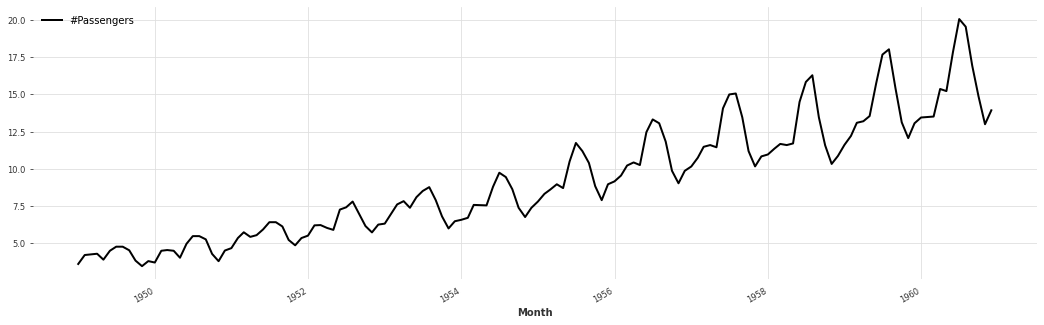

In [6]:
# plot the observations
plt.figure(100, figsize=(18, 5))
ts.plot();

Мы видим четкую тенденцию к росту и, похоже, стабильную годовую сезонность. Амплитуда сезонных пиков увеличивается со временем, поэтому сезонность должна быть мультипликативной, а не аддитивной.
Darts предлагает функцию check_seasonality(), которая оценивает автокорреляционную функцию ACF. Она позволяет нам проверить наши визуальные подсказки, подтвердив сезонность в 12 месяцев.

In [7]:
# определение периода сезонной компоненты
mseas=MSEAS
for m in range(2, MSEAS):
    is_seasonal, mseas = check_seasonality(ts, m=m, alpha=ALPHA, max_lag=MSEAS)
    if is_seasonal:
        break

print("seasonal? " + str(is_seasonal))
if is_seasonal:
    print('There is seasonality of order {} months'.format(mseas))

seasonal? True
There is seasonality of order 12 months


Далее мы используем модель ETS для выделения тренда и сезонного компонента. В Darts используется метод ETS из пакета statsmodels.

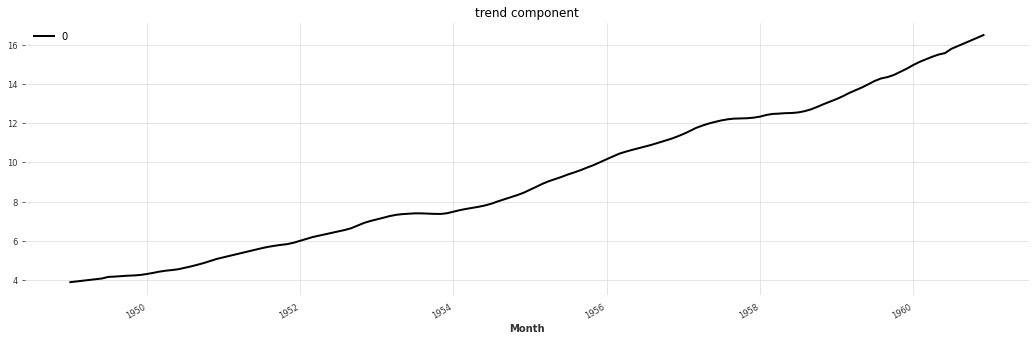

In [8]:
# Анализ ETS: попытка выявить тренд и сезонные компоненты
ts_trend, ts_seas = extract_trend_and_seasonality(ts=ts, freq=mseas)

plt.figure(100, figsize=(18, 5))
ts_trend.plot()
plt.title("trend component");

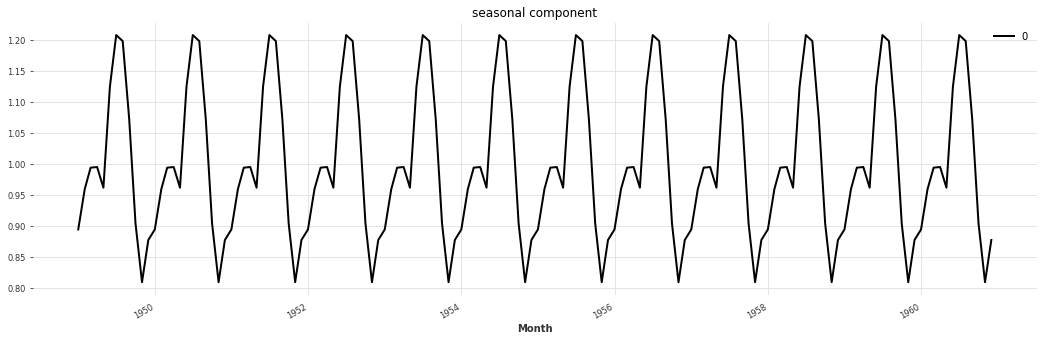

In [9]:
plt.figure(100, figsize=(18, 5))
ts_seas.plot()
plt.title("seasonal component");

Чтобы подготовить данные для прогноза, мы разделяем временной ряд на обучающий и тестовый наборы.

Если константа TRAIN имеет тип string, преобразуем ее в метку времени pandas.

В то время как плавающее значение между 0 и 1 будет интерпретироваться как процентная доля временного ряда, которую скрипт должен зарезервировать для обучения.

Если бы TRAIN было целым числом, функция split() интерпретировала бы его как индекс, на котором должен закончиться набор данных для обучения.

Нейронные сети чувствительны к изменениям масштаба. Поэтому нам необходимо масштабировать ежедневное количество пассажиров. Чтобы исключить утечку, мы не используем `Scaler` к тестовому набору. 
После обучения мы применяем его к тестовым данным.

In [9]:
# train/test
if isinstance(TRAIN, str):
    split = pd.Timestamp(TRAIN)
else:
    split = TRAIN
ts_train, ts_test = ts.split_after(split)

# масштабируйте временной ряд на обучающем наборе transformer = Scaler()
transformer = Scaler()
ts_ttrain = transformer.fit_transform(ts_train)
ts_ttest = transformer.transform(ts_test)
ts_t = transformer.transform(ts)

В терминологии регрессии ковариаты называются регрессорами или независимыми переменными. В нашем примере данных нет экзогенных переменных, которые повлияли бы на количество пассажиров в 1950-х годах. Безусловно, расширение маршрутов полетов на большее количество направлений или снижение цен на билеты оказали бы значительное влияние на количество пассажиров. У нас нет под рукой таких исходных данных.

Вместо этого мы выведем две ковариаты из временных меток, которые мы нашли в нашем источнике, что облегчит выделение закономерностей на оси времени для любого типа нейронных сетей. 

- В строке 2 ниже мы используем функцию Darts datetime_atribute_timeseries() для выделения года. 
- В строке 3 мы получаем месяцы как еще одну ковариату и объединяем ее (складываем) с годами. 
- В строке 4 добавляется последовательный целочисленный индекс. Вместе эти три переменные образуют временной ряд ковариатов, cov.
- В строке 11 мы разделяем ковариаты между обучающим и тестовым множеством. Масштабирование, применяемое к обучающей части, снова необходимо, чтобы сделать ковариаты удобоваримыми для нейронных сетей.

In [11]:
# create covariates: year, month, and integer index series
cov = datetime_attribute_timeseries(ts, attribute="year", one_hot=False)
cov = cov.stack(datetime_attribute_timeseries(ts, attribute="month", one_hot=False))
cov = cov.stack(TimeSeries.from_times_and_values(
                                    times=ts.time_index, 
                                    values=np.arange(len(ts)), 
                                    columns=["linear_increase"]))
cov = cov.astype(np.float32)

# train/test
train_cov, test_cov = cov.split_after(split)

# rescale the covariates: fit on the training set
scaler = Scaler()
scaler.fit(train_cov)
tcov = scaler.transform(cov)

# Naive Baseline Forecast

Любой метод прогнозирования, такой как Temporal Fusion Transformer, считается полезным, если он обеспечивает более высокую точность, чем более простая базовая модель прогнозирования. Если выбранная нами метрика точности - средняя абсолютная процентная ошибка - хуже того, что достигается базовой моделью, то более сложная модель будет считаться бесполезной.

Наивный сезонный прогноз просто предполагает, что значения временного ряда будут повторяться каждые K временных шагов. Функция `check_seasonality()`, которую мы оценивали выше, подтвердила сезонность `mseas = 12` месяцев, которую мы передаем в прогнозист.

Но мы также наблюдали устойчивый восходящий тренд. Таким образом, прогноз должен отражать, что сезонные пики не остаются постоянными, а растут из года в год. Наивный дрейф рисует прямую линию между первым и последним наблюдениями, чтобы отразить эту линию тренда.

Сумма наивного дрейфа и сезонности дает прогнозную кривую, которая относительно точно отражает фактические наблюдения в тестовом наборе, хотя она не совсем точно отражает пик количества пассажиров в самом конце тестового набора, в 1960 году.
`MAPE` тестового набора составляет всего 5,71%, что означает, что это хорошо управляемый временной ряд с надежными, регулярными закономерностями. Это эталон, с которым должны будут конкурировать более сложные модели прогнозирования.

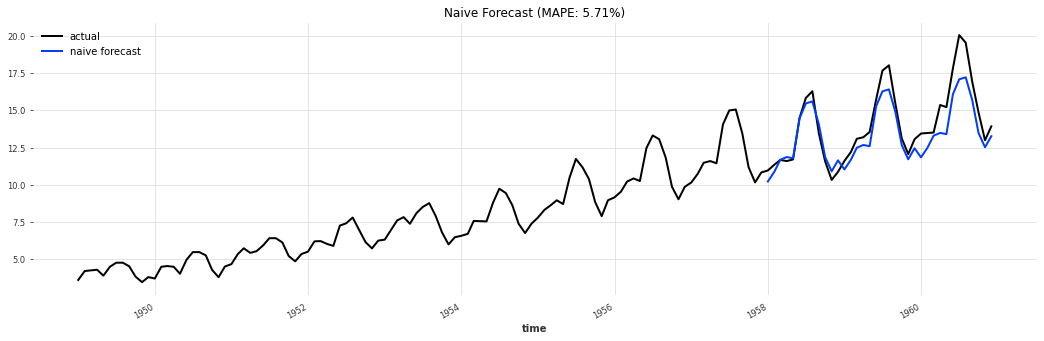

In [12]:
# naive seasonal forecast
modelNs = NaiveSeasonal(K=mseas)
modelNs.fit(ts_train)
ts_predNs = modelNs.predict(len(ts_test))

# naive drift (trend) forecast
modelNd = NaiveDrift()
modelNd.fit(ts_train)
ts_predNd = modelNd.predict(len(ts_test))

ts_predN = ts_predNd + ts_predNs - ts_train.last_value()

plt.figure(100, figsize=(18, 5))
ts.plot(label="actual")
ts_predN.plot(label="naive forecast")
plt.title("Naive Forecast (MAPE: {:.2f}%)".format(mape(ts_test, ts_predN)))
plt.legend();

# Exponential Smoothing Baseline Forecast

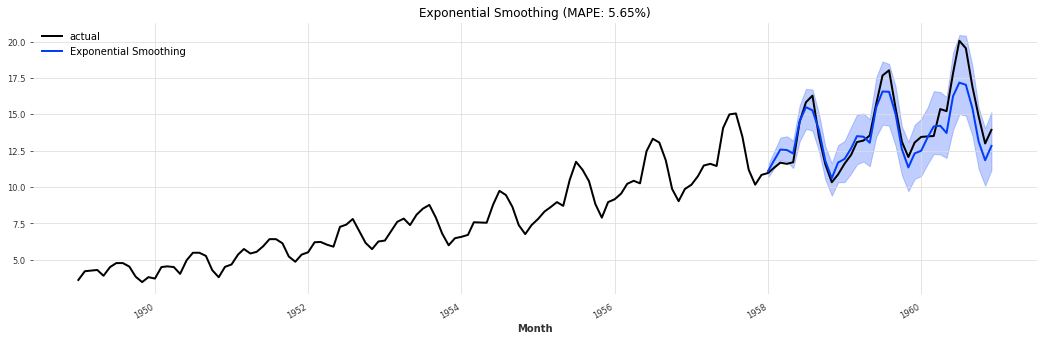

In [14]:
modelX = ExponentialSmoothing(
                seasonal_periods=12, 
                seasonal=ModelMode.MULTIPLICATIVE)
modelX.fit(ts_train)
ts_predX = modelX.predict(  n=len(ts_test), 
                            num_samples=N_SAMPLES)

plt.figure(100, figsize=(18, 5))
ts.plot(label="actual")
ts_predX.plot(label="Exponential Smoothing")
plt.title("Exponential Smoothing (MAPE: {:.2f}%)".format(mape(ts_test, ts_predX)))
plt.legend();

# Fit the Temporal Fusion Transformer

Модель TFT настроена с гиперпараметрами, которые мы перечислили в верхней ячейке блокнота.
Поскольку мы хотим получить вероятностный прогноз, мы советуем прогнозисту применить квантильную регрессию, используя в качестве параметра список констант, `QUANTILES`, который выстраивает частоты от 0,01 до 0,99. Для детерминированного прогноза мы бы вместо этого использовали традиционную функцию потерь, `loss_fn`.

In [14]:
model = TFTModel(   input_chunk_length=INLEN,
                    output_chunk_length=N_FC,
                    hidden_size=HIDDEN,
                    lstm_layers=1,  #LSTMLAYERS,
                    num_attention_heads=ATTHEADS,
                    dropout=DROPOUT,
                    batch_size=BATCH,
                    n_epochs=EPOCHS,
                    likelihood=QuantileRegression(quantiles=QUANTILES), 
                    # loss_fn=MSELoss(),
                    random_state=RAND, 
                    force_reset=True)

Обучаем модель. Ее параметр `future_covariates` состоит из года, месяцев и целочисленного индекса, который мы получили из временных меток.

In [15]:
# training
model.fit(  ts_ttrain, 
            future_covariates=tcov, 
            verbose=True)

  0%|          | 0/500 [00:00<?, ?it/s]

# Predict the Test Set

После завершения обучения мы прогнозируем ежедневное количество пассажиров в тестовом наборе данных.
Если `num_samples` имеет целочисленное значение больше 1, мы получаем вероятностный прогноз, что подтверждает атрибут временного ряда Darts: `is_probabilistic`

In [16]:
# testing: generate predictions
ts_tpred = model.predict(   n=len(ts_test), 
                            num_samples=N_SAMPLES,   
                            n_jobs=N_JOBS)

In [17]:
print("Do the predictions constitute a probabilistic time series?", ts_tpred.is_probabilistic)

Do the predictions constitute a probabilistic time series? True


Далее мы напишем вспомогательный метод plot_predict, который будет рисовать прогнозную кривую, используя функцию `Darts plot()` для объектов временных рядов. В качестве аргументов он принимает выбранные нижнюю и верхнюю границы для перцентильной полосы относительно медианной кривой прогноза. Помните, что мы определили три таких перцентильных скобки в верхней части Jupyter-блокнота: 1%/99%, 5%/95%, 10%/90%.

В строках 9-11 используется первая и третья пара. Вторая пара, 5%/95%, сделала бы график слишком перегруженным, поэтому я закомментировал ее строку кода.

Линия 12 рисует среднюю прогнозную кривую. В качестве альтернативы можно выбрать медиану, установив параметр `central_quantile` равным 0.5.

В строке 21 вызывается вспомогательный метод `plot_predict` после изменения масштабного преобразования, которое мы применили к исходным данным перед запуском трансформатора слияния.

In [18]:
# testing: helper function: plot predictions
def plot_predict(ts_actual, ts_test, ts_pred):
    
    ## plot time series, limited to forecast horizon
    plt.figure(figsize=FIGSIZE)
    
    ts_actual.plot(label="actual")                                       # plot actual
    
    ts_pred.plot(low_quantile=qL1, high_quantile=qU1, label=label_q1)    # plot U1 quantile band
    #ts_pred.plot(low_quantile=qL2, high_quantile=qU2, label=label_q2)   # plot U2 quantile band
    ts_pred.plot(low_quantile=qL3, high_quantile=qU3, label=label_q3)    # plot U3 quantile band
    ts_pred.plot(central_quantile="mean", label="expected")              # plot "mean" or median=0.5
    
    plt.title("TFT: test set (MAPE: {:.2f}%)".format(mape(ts_test, ts_pred)))
    plt.legend();    

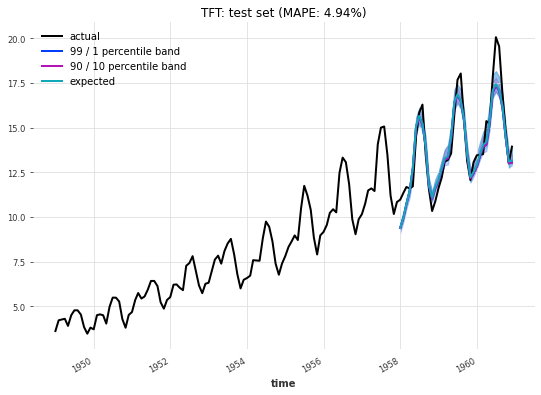

In [19]:
# testing: call helper function: plot predictions
ts_pred = transformer.inverse_transform(ts_tpred)
plot_predict(ts, ts_test, ts_pred)

Прогнозируемые значения достаточно хорошо согласуются с фактическим количеством пассажиров в тестовом окне. MAPE TFT ниже, чем ошибка любого из базовых прогнозов.

Давайте увеличим масштаб тестового набора, чтобы можно было различить перцентильные полосы. Ошибки прогнозирования во время обучения были небольшими, поэтому перцентильные полосы сравнительно плотно прилегают к среднему значению. В 1960 году количество пассажиров выросло больше, чем предполагала тенденция предыдущих лет. Именно по этой причине TFT недооценивает пик, как и наивный прогноз и экспоненциальное сглаживание. Это было изменение закономерности, которое не выявил набор данных для обучения. Поскольку оно произошло в самом конце тестового набора данных, период обучения должен был охватить более 90% всего временного ряда, чтобы получить шанс уловить его.

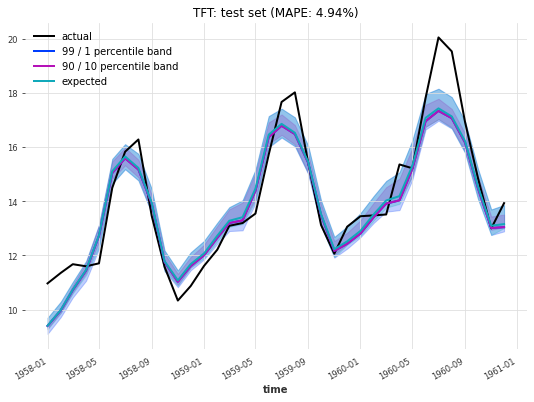

In [20]:
# testing: call helper function: plot predictions, focus on test set
ts_pred = transformer.inverse_transform(ts_tpred)
ts_actual = ts[ ts_tpred.start_time(): ts_tpred.end_time() ]  # фактические значения в горизонте прогноза
plot_predict(ts_actual, ts_test, ts_pred)

Чтобы вычислить процентили прогноза,

- создаем новый фрейм данных dfY в строке 2,
- заполним его фактическими наблюдениями в строке 13;
- и выбираем перцентили, которые мы хотим табулировать, в строке 16.
- Компоновка списка в строке 17 вызывает вспомогательную функцию predQ() для каждого из этих семи перцентилей.
- Функция Darts `quantile_timeseries()` вычисляет прогнозный перцентиль/квантиль для каждого месяца в тестовом наборе, в строке 6.
- Строки 7 и 8 преобразуют объект квантильного временного ряда в обычную серию pandas и вставляют его в качестве квантильного столбца в кадр данных dfY.
- "Q50" обозначает то, что было бы точечной оценкой в детерминированном прогнозе. Затем другие квантили заключают в скобки эту центральную точку прогноза Q50 в каждом месяце.

In [21]:
# тестирование: собрать перцентили предсказаний в кадр данных dfY
dfY = pd.DataFrame()

# helper method: calculate percentiles of predictions
def predQ(ts_tpred, q):
    ts_t = ts_tpred.quantile_timeseries(q)         # процентиль прогнозов
    ts = transformer.inverse_transform(ts_t)       # обратное преобразование перцентиля
    s = TimeSeries.pd_series(ts)
    header = "Q" + format(int(q*100), "02d")
    dfY[header] = s

# Заполните столбец Actual в новом кадре данных
dfY["Actual"] = TimeSeries.pd_series(ts_actual)

# вызов вспомогательной функции: перцентили предсказаний
quantiles = [0.5, qU1, qU2, qU3, qL3, qL2, qL1]
_ = [predQ(ts_tpred, q) for q in quantiles]
dfY.iloc[np.r_[0:2, -2:0]]


,Actual,Q50,Q99,Q95,Q90,Q10,Q05,Q01
Month,,,,,,,,
1958-01-01,10.97,9.39,9.70,9.69,9.47,9.30,9.27,9.10
1958-02-01,11.36,9.97,10.29,10.29,10.10,9.90,9.87,9.72
1960-11-01,13.00,13.02,13.70,13.70,13.44,12.95,12.76,12.76
1960-12-01,13.94,13.05,13.87,13.86,13.51,13.05,13.02,12.89


# Predict the Past: Backtesting

Функция `historical_forecasts` позволяет нам вычислять прогнозы по всей временной оси исходного временного ряда, а не только для тестового набора.

In [22]:
# backtest the model: predictions vs actual values

# start: at 10% of time series
STARTBACKT = ts.get_timestamp_at_point(point=max(0.2, INLEN))  #pd.Timestamp("19500301")
print("start:",STARTBACKT)

# горизонт прогнозирования: до конца тестового периода
tdiff = (   pd.to_datetime(ts.end_time()).to_period("M") - 
            pd.to_datetime(STARTBACKT).to_period("M")).n
print("months:",tdiff)

ts_tbacktest = model.historical_forecasts(  series=ts_t,
                                            past_covariates=None, 
                                            future_covariates=tcov,
                                            start=STARTBACKT,  
                                            num_samples=N_SAMPLES,
                                            forecast_horizon=tdiff,
                                            stride=12,
                                            last_points_only=False,
                                            retrain=False,
                                            verbose=True)

start: 1951-09-01 00:00:00
months: 111


  0%|          | 0/1 [00:00<?, ?it/s]

In [23]:
# backtesting: вспомогательная функция: построение графика прогнозов 
def plot_backtest(ts_backtest, ts_actual, transformer):
    plt.figure(figsize=FIGSIZE)
    ts_actual.plot(label="actual")
    ts_backtest.plot(low_quantile=qL1, high_quantile=qU1, label=label_q1)
    ts_backtest.plot(low_quantile=qL3, high_quantile=qU3, label=label_q3)
    plt.legend()
    MAPE = "MAPE: {:.2f}%".format(mape(ts_actual, ts_backtest))
    plt.title(  "TFT: backtest from " + \
                format(ts_backtest.start_time(), "%Y.%m") + \
                " to " + format(ts_backtest.end_time(), "%Y.%m") + \
                "  (" + MAPE + ")");

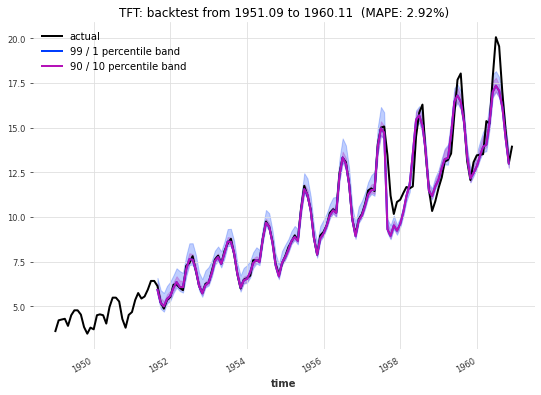

In [24]:
# plot backtest
ts_backtest = transformer.inverse_transform(ts_tbacktest)

plot_backtest(  ts_backtest=concatenate(ts_backtest),
                ts_actual=ts,
                transformer=transformer)

Мы видим, что средняя абсолютная процентная ошибка составляет всего 3,20% для данных, охватывающих период с 1950 по 1960 год. Как и следовало ожидать, модель достигла лучшего соответствия данным, на которых она была обучена, чем на тестовом наборе. Большая часть разницы в точности, от 5,3% до 3,2%, приходится на последний год, 1960, когда количество пассажиров превысило долгосрочную тенденцию.

# Predict the Future: Out of Sample

Как мы можем получить прогнозы вне выборки, за пределами последнего 1960 года?

Во-первых, нам нужно создать ковариаты, выходящие за рамки тех, что мы находим в исходных данных.
- Используя функцию Darts `datetime_attribute_timeseries()`, мы определяем диапазон дат pandas `date_range` с частотой "MS (начало месяца)" в строке 8, а затем извлекаем его годы.
- То же самое мы делаем для месяцев и складываем их с годами.
- В строках 17-20, используя функцию `from_times_and_values`, мы получаем последовательный целочисленный индекс, а затем прикрепляем его к двум другим ковариатам, годам и месяцам.

Как обычно, в строке 23 нам нужно масштабировать ковариаты.
Ковариаты охватывают месяцы с января 1958 года по декабрь 1963 года - шесть лет, которые следуют за окончанием периода обучения.
На этом горизонте в 72 месяца мы вызываем функцию `predict()` в строке 29. Затем в строке 31 происходит обратное преобразование масштаба, а в строках с 33 по 44 строятся кривая прогноза и ее перцентильные полосы.

In [25]:
# create future covariates: year, month, integer index
FC_HORIZ = 72                       # месяцев после окончания обучения
start = ts.start_time()
n_per = len(ts_train) + FC_HORIZ    # установите максимальный горизонт для создания ковариатов

# create covariates from beginning of training data to end of forecast horizon
ts_year = datetime_attribute_timeseries(
                pd.date_range(start=start, periods=n_per, freq="MS"),  #, closed="right"),
                attribute="year", 
                one_hot=False)
ts_month = datetime_attribute_timeseries(
                pd.date_range(start=start, periods=n_per, freq="MS"),  
                attribute="month", 
                one_hot=False)
cov = ts_year.stack(ts_month)
# combine year and month with integer index as third covariate
cov = cov.stack(TimeSeries.from_times_and_values(
                times=cov.time_index, 
                values=np.arange(n_per), 
                columns=['linear_increase']))

cov = cov.astype(np.float32)
tcov = scaler.transform(cov)
print("start:", cov.start_time(), "; end:",cov.end_time())


start: 1949-01-01 00:00:00 ; end: 1963-12-01 00:00:00


start: 1958-01-01 00:00:00 ; end: 1963-12-01 00:00:00


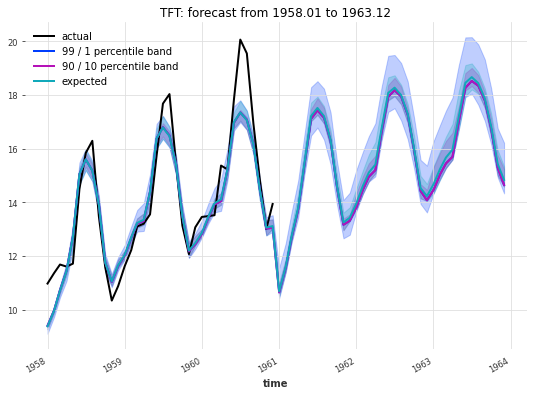

In [26]:
# generate future, out-of-sample predictions
ts_tpred = model.predict(n=FC_HORIZ, future_covariates=tcov, num_samples=N_SAMPLES)
print("start:", ts_tpred.start_time(), "; end:",ts_tpred.end_time())
ts_pred = transformer.inverse_transform(ts_tpred)

plt.figure(figsize=FIGSIZE)
    
ts_actual = ts.slice_intersect(other=ts_pred)
ts_actual.plot(label="actual")     

ts_pred.plot(low_quantile=qL1, high_quantile=qU1, label=label_q1)    # plot U1 quantile band
ts_pred.plot(low_quantile=qL3, high_quantile=qU3, label=label_q3)    # plot U3 quantile band
ts_pred.plot(central_quantile="mean", label="expected")              # plot "mean" or median=0.5
plt.title(  "TFT: forecast" + \
            " from " + format(ts_tpred.start_time(), "%Y.%m") + \
            " to " + format(ts_tpred.end_time(), "%Y.%m"));  
plt.legend(); 

In [27]:
# forecast: collect the prediction percentiles in a dataframe
dfY = pd.DataFrame()
# call helper function predQ: percentiles of predictions
_ = [predQ(ts_tpred, q) for q in quantiles]

dfY["Actual"] = TimeSeries.pd_series(ts_actual)

dfY.iloc[np.r_[0:2, -2:0]]

,Q50,Q99,Q95,Q90,Q10,Q05,Q01,Actual
time,,,,,,,,
1958-01-01,9.39,9.47,9.46,9.46,9.27,9.26,9.10,10.97
1958-02-01,9.97,10.10,10.06,10.06,9.89,9.87,9.72,11.36
1963-11-01,15.29,16.75,15.94,15.76,14.99,14.99,14.93,NaN
1963-12-01,14.64,16.22,15.33,15.24,14.58,14.58,14.33,NaN


# Save and Reload a Model

Мы получаем путь к текущему рабочему каталогу, определяем имя файла и сохраняем модель в виде файла .pth.tar.

In [28]:
import os
mpath = os.path.abspath(os.getcwd()) + "\_TFTmodel.pth.tar"
print("saved model:", mpath)
model.save_model(mpath)

saved model: /home/jupyter/heiko\_TFTmodel.pth.tar


Функция `load_model()` забирает tar-файл обратно в оперативную память.

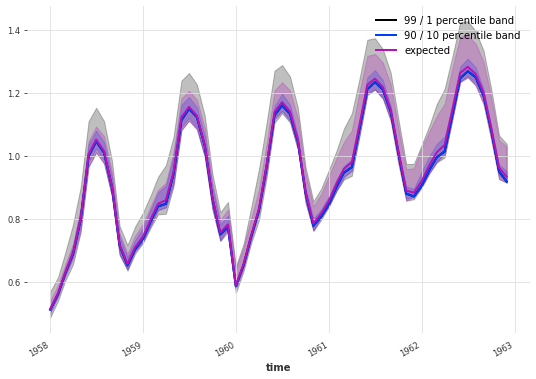

In [29]:
# load a saved model and generate n=60 predictions
mTFT = model.load_model(mpath)
ts_tpred = mTFT.predict(n=60, future_covariates=tcov, num_samples=N_SAMPLES)

plt.figure(figsize=FIGSIZE)
         
ts_tpred.plot(low_quantile=qL1, high_quantile=qU1, label=label_q1)    # plot U1 quantile band
ts_tpred.plot(low_quantile=qL3, high_quantile=qU3, label=label_q3)    # plot U3 quantile band
ts_tpred.plot(central_quantile="mean", label="expected")              # plot "mean" or median=0.5
    
plt.legend(); 

# GridSearch TFT

Библиотека Darts позволяет нам запустить сеточный поиск гиперпараметров модели TFT. Поиск может охватывать все пространство поиска - или можно посоветовать метод случайных выборок и оценить только определенный процент всех возможных кортежей параметров.
В настоящее время сеточный поиск в Darts работает для детерминированных моделей, но не оценивает вероятностные прогнозы. Мы будем искать наилучшую детерминистическую параметризацию модели TFT.
Мы начнем с определения словаря параметров в строке 2. Его ключи должны состоять из имен управляющих параметров TFT. Его значения состоят из списков альтернативных значений параметров, которые мы хотим протестировать.
В примере ниже вы видите, что я определил относительно узкое пространство поиска, чтобы ограничить время, необходимое для оценки каждого возможного кортежа. Для большинства параметров я перечислил всего два (или даже одно) значение, которые необходимо исследовать с помощью сеточного поиска.

- Лучшая модель будет определена по метрике `mape`, вычисленной на тестовом множестве.
- `n_jobs` информирует алгоритм поиска о максимальном количестве процессоров, на которое он может претендовать.
- `n_random_samples` может быть задано в виде дроби между 0 и 1. Если значение меньше 1, то метод будет оценивать не все кортежи параметров в пространстве поиска, а только заданную долю.

In [30]:
# randomized gridsearch
parameters = {  "input_chunk_length":[16, 32], 
                "hidden_size":[32, 64], 
                "lstm_layers":[1], 
                "num_attention_heads":[2, 3], 
                "dropout":[0.1], 
                "batch_size":[32, 64], 
                "n_epochs":[1000]
                }

res = TFTModel.gridsearch(    
                            parameters=parameters,
                            series=ts_ttrain, 
                            future_covariates=tcov, 
                            val_series=ts_ttest,   
                            start=0.1,                 # starting point in training set 
                            last_points_only=False, 
                            metric=mape, 
                            reduction=np.mean, 
                            n_jobs=N_JOBS, 
                            n_random_samples=0.99,      # % of full search space to evaluate
                            verbose=True)
bestmodel, dict_bestparams = res

  0%|          | 0/15 [00:00<?, ?it/s]

[2022-01-25 04:26:07,340] INFO | darts.models.forecasting.torch_forecasting_model | Train dataset contains 92 samples.
[2022-01-25 04:26:07,340] INFO | darts.models.forecasting.torch_forecasting_model | Train dataset contains 92 samples.
[2022-01-25 04:26:07,357] INFO | darts.models.forecasting.torch_forecasting_model | Time series values are 32-bits; casting model to float32.
[2022-01-25 04:26:07,357] INFO | darts.models.forecasting.torch_forecasting_model | Time series values are 32-bits; casting model to float32.
[2022-01-25 04:26:09,823] INFO | darts.models.forecasting.torch_forecasting_model | Train dataset contains 92 samples.
[2022-01-25 04:26:09,823] INFO | darts.models.forecasting.torch_forecasting_model | Train dataset contains 92 samples.
[2022-01-25 04:26:09,823] INFO | darts.models.forecasting.torch_forecasting_model | Train dataset contains 92 samples.
[2022-01-25 04:26:09,823] INFO | darts.models.forecasting.torch_forecasting_model | Train dataset contains 92 samples.
[2

In [31]:
mpath = os.path.abspath(os.getcwd()) + "\_TFTbestmodel.pth.tar"
print("saved model:", mpath)
bestmodel.save_model(mpath)

saved model: /home/jupyter/heiko\_TFTbestmodel.pth.tar


In [32]:
dict_bestparams

{'input_chunk_length': 16,
 'hidden_size': 64,
 'lstm_layers': 1,
 'num_attention_heads': 2,
 'dropout': 0.1,
 'batch_size': 64,
 'n_epochs': 1000}

In [33]:
bestmodel._model_params

((),
 {'input_chunk_length': 16,
  'hidden_size': 64,
  'lstm_layers': 1,
  'num_attention_heads': 2,
  'dropout': 0.1,
  'batch_size': 64,
  'n_epochs': 1000})

In [34]:
# training
bestmodel.fit(  ts_ttrain, 
                future_covariates=tcov, 
                verbose=True)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [35]:
n_FC = len(ts_test)
ts_tpred =  bestmodel.predict(n_FC)
ts_pred = transformer.inverse_transform(ts_tpred)
MAPE = "MAPE after randomized gridsearch: {:.2f}%".format(mape(ts_actual, ts_pred))
print(MAPE)

MAPE after randomized gridsearch: 6.20%


Точность вышла даже хуже, значит сетка гиперпараметров была неудачная.